# Домашнее задание 1

Для запуска установите зависимости и запустите ноутбук. При первом запуске первая ячейка скачает отзывы и метаданные в папку data; последующие ячейки обработают данные.

Я сравниваю пять моделей персональных рекомендаций top-10 на датасете Amazon Video Games (2018). Отзыв с оценкой 4–5 считаю релевантным; 1–3 — наблюдаемой отрицательной меткой для обучаемых моделей. Источник — [страница набора UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html). Данные в ноутбуке скачиваются при первом запуске и не входят в комплект.

В отзывах есть reviewerID, asin, overall, unixReviewTime; в метаданных — название товара, категории и бренд. Это явные оценки с временными метками. Категория и бренд доступны до рекомендации, поэтому подходят как признаки FM. Для KNN и iALS матрицу user-item храню разреженно (CSR/CSC). Точная EASE решает систему с плотной матрицей Грама по товарам: для исходных 71 982 товаров только одна матрица float64 занимает около 38,6 ГиБ, без временных массивов. Поэтому для точной EASE ограничиваю общий каталог 1 800 популярными товарами, выбранными по ранним отзывам; все модели сравниваются на одном каталоге известных товаров.


In [1]:
from pathlib import Path
import csv
import gzip
import json

import certifi
import requests

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
REVIEWS_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFiles/Video_Games.json.gz"
METADATA_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Video_Games.json.gz"
REVIEWS_PATH = DATA_DIR / "reviews_Video_Games.json.gz"
METADATA_PATH = DATA_DIR / "meta_Video_Games.json.gz"
COMPACT_PATH = DATA_DIR / "reviews_compact.csv.gz"
AUDIT_PATH = DATA_DIR / "reviews_audit.json"

def download(url, path):
    """Download from the primary UCSD host with TLS verification enabled."""
    if path.exists():
        return
    partial = path.with_suffix(path.suffix + ".part")
    with requests.get(url, stream=True, timeout=(30, 180), verify=certifi.where()) as response:
        response.raise_for_status()
        with partial.open("wb") as output:
            for block in response.iter_content(1024 * 1024):
                if block:
                    output.write(block)
    partial.replace(path)

download(REVIEWS_URL, REVIEWS_PATH)
download(METADATA_URL, METADATA_PATH)

if not COMPACT_PATH.exists():
    raw_count, missing_count, invalid_rating_count, count = 0, 0, 0, 0
    with gzip.open(REVIEWS_PATH, "rt", encoding="utf-8") as source, \
         gzip.open(COMPACT_PATH, "wt", encoding="utf-8", newline="") as target:
        writer = csv.writer(target)
        writer.writerow(["reviewerID", "asin", "overall", "unixReviewTime"])
        for line in source:
            row = json.loads(line)
            raw_count += 1
            required = ("reviewerID", "asin", "overall", "unixReviewTime")
            if any(row.get(key) is None for key in required):
                missing_count += 1
                continue
            rating = float(row["overall"])
            if not 1 <= rating <= 5:
                invalid_rating_count += 1
                continue
            writer.writerow((row["reviewerID"], row["asin"], rating, int(row["unixReviewTime"])))
            count += 1
    AUDIT_PATH.write_text(json.dumps({
        "raw_records": raw_count,
        "missing_required_fields": missing_count,
        "invalid_ratings": invalid_rating_count,
        "valid_rows": count,
    }, indent=2), encoding="utf-8")
    print(f"Сохранено валидных отзывов: {count:,} из {raw_count:,}")
else:
    if AUDIT_PATH.exists():
        audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
        print(f"Валидных отзывов в кэше: {audit['valid_rows']:,} из {audit['raw_records']:,}")
    else:
        print("Использую компактный кэш:", COMPACT_PATH)

if AUDIT_PATH.exists():
    raw_audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))


Валидных отзывов в кэше: 2,565,349 из 2,565,349


In [2]:
import gzip
import json

import numpy as np
import pandas as pd

SEED = 42
CATALOG_SIZE = 1800
TARGET_INTERACTIONS = 200_000

reviews = pd.read_csv(
    COMPACT_PATH,
    compression="gzip",
    dtype={"reviewerID": "string", "asin": "string", "overall": "float32", "unixReviewTime": "int64"},
)
raw_review_count = len(reviews)
reviews = reviews.dropna(subset=["reviewerID", "asin", "overall", "unixReviewTime"])
reviews = reviews[reviews["overall"].between(1, 5)].copy()
source_users = reviews.reviewerID.nunique()
source_items = reviews.asin.nunique()
reviews["reviewerID"] = reviews["reviewerID"].astype("category")
reviews["asin"] = reviews["asin"].astype("category")

reviews = reviews.sort_values(["reviewerID", "asin", "unixReviewTime"], kind="mergesort")
reviews = reviews.drop_duplicates(["reviewerID", "asin"], keep="last")
reviews = reviews.sort_values(["reviewerID", "unixReviewTime", "asin"], kind="mergesort").reset_index(drop=True)
deduplicated_count = len(reviews)

user_sizes = reviews.groupby("reviewerID", observed=True).size()
position = reviews.groupby("reviewerID", observed=True).cumcount().to_numpy()
user_n = reviews["reviewerID"].map(user_sizes).to_numpy(dtype=np.int32)
early_train = position < np.floor(0.8 * user_n)
top_items = (
    reviews.loc[early_train].groupby("asin", observed=True).size()
    .nlargest(CATALOG_SIZE).index
)
reviews = reviews.loc[reviews["asin"].isin(top_items)].copy()
after_catalog_count = len(reviews)

def five_core(frame, min_events=5):
    while True:
        user_counts = frame.groupby("reviewerID", observed=True).size()
        item_counts = frame.groupby("asin", observed=True).size()
        keep_users = user_counts.index[user_counts >= min_events]
        keep_items = item_counts.index[item_counts >= min_events]
        filtered = frame.loc[frame.reviewerID.isin(keep_users) & frame.asin.isin(keep_items)]
        if len(filtered) == len(frame):
            return filtered.copy()
        frame = filtered

reviews = five_core(reviews)
after_five_core_count = len(reviews)

if len(reviews) > TARGET_INTERACTIONS:
    sizes = reviews.groupby("reviewerID", observed=True).size()
    sampled_users = sizes.index.to_numpy(copy=True)
    np.random.default_rng(SEED).shuffle(sampled_users)
    chosen, total = [], 0
    for user in sampled_users:
        chosen.append(user)
        total += int(sizes.loc[user])
        if total >= TARGET_INTERACTIONS:
            break
    reviews = five_core(reviews.loc[reviews.reviewerID.isin(chosen)].copy())
after_user_sample_count = len(reviews)

reviews = reviews.sort_values(["reviewerID", "unixReviewTime", "asin"], kind="mergesort").reset_index(drop=True)
user_sizes = reviews.groupby("reviewerID", observed=True).size()
position = reviews.groupby("reviewerID", observed=True).cumcount().to_numpy()
user_n = reviews.reviewerID.map(user_sizes).to_numpy(dtype=np.int32)
train_end = np.minimum(np.maximum(np.floor(0.8 * user_n).astype(int), 3), user_n - 2)
valid_end = np.minimum(np.maximum(np.floor(0.9 * user_n).astype(int), train_end + 1), user_n - 1)
reviews["split"] = np.where(position < train_end, "train", np.where(position < valid_end, "validation", "test"))

user_ids = sorted(map(str, reviews.reviewerID.astype("string").unique()))
item_ids = sorted(map(str, reviews.asin.astype("string").unique()))
user_to_idx = {value: index for index, value in enumerate(user_ids)}
item_to_idx = {value: index for index, value in enumerate(item_ids)}
reviews["user_id"] = reviews.reviewerID.astype("string").map(user_to_idx).astype(np.int32)
reviews["item_id"] = reviews.asin.astype("string").map(item_to_idx).astype(np.int32)
reviews["rating"] = reviews.overall.astype(np.float32)
reviews["timestamp"] = reviews.unixReviewTime.astype(np.int64)
interactions = reviews[["user_id", "item_id", "rating", "timestamp", "asin", "split"]].reset_index(drop=True)
train = interactions.loc[interactions.split == "train"].copy()
validation = interactions.loc[interactions.split == "validation"].copy()
test = interactions.loc[interactions.split == "test"].copy()

selected_asins = set(item_ids)
meta_rows = {}
with gzip.open(METADATA_PATH, "rt", encoding="utf-8") as source:
    for line in source:
        record = json.loads(line)
        asin = str(record.get("asin", ""))
        if asin not in selected_asins:
            continue
        branches = record.get("category") or record.get("categories") or []
        if branches and not isinstance(branches[0], list):
            branches = [branches]
        levels = []
        for branch in branches:
            if isinstance(branch, list):
                levels = [str(value).strip() for value in branch if str(value).strip()]
                levels = [value for value in levels
                          if value.casefold() != "video games" and not value.startswith("<")]
                if levels:
                    break
        meta_rows[asin] = {
            "title": record.get("title") or "Unknown title",
            "category": levels[-1] if levels else "Unknown category",
            "parent_category": levels[-2] if len(levels) > 1 else "Unknown parent",
            "brand": record.get("brand") or "Unknown brand",
        }

metadata = pd.DataFrame.from_dict(meta_rows, orient="index").reindex(item_ids)
metadata.index.name = "asin"
metadata = metadata.reset_index()
metadata["item_id"] = metadata.asin.map(item_to_idx).astype(np.int32)
for column in ("title", "category", "parent_category", "brand"):
    metadata[column] = metadata[column].fillna("Unknown").astype(str)

n_users, n_items = len(user_ids), len(item_ids)
candidate_items = np.sort(train.item_id.unique().astype(np.int32))
metadata_coverage = {
    "Названия": float(metadata.title.ne("Unknown title").mean()),
    "Категории": float(metadata.category.ne("Unknown category").mean()),
    "Родительские категории": float(metadata.parent_category.ne("Unknown parent").mean()),
    "Бренды": float(metadata.brand.ne("Unknown brand").mean()),
}
stats = {
    "Строк в источнике": raw_audit["raw_records"],
    "Пропущены обязательные поля": raw_audit["missing_required_fields"],
    "Некорректные оценки": raw_audit["invalid_ratings"],
    "Валидные отзывы": raw_review_count,
    "Уникальные user-item после дедупликации": deduplicated_count,
    "Дубли user-item удалены": raw_review_count - deduplicated_count,
    "Пользователи / товары в исходной категории": f"{source_users:,} / {source_items:,}",
    "После выбора каталога": after_catalog_count,
    "После фильтрации 5-core": after_five_core_count,
    "После выборки пользователей": after_user_sample_count,
    "Взаимодействия после фильтрации и подвыборки": len(interactions),
    "Train": len(train), "Validation": len(validation), "Test": len(test),
    "Пользователи": n_users, "Товары": n_items,
    "Товары-кандидаты (есть в train)": len(candidate_items),
    "Плотность train": len(train) / (n_users * n_items),
    "Seed": SEED, "Размер каталога до фильтрации": CATALOG_SIZE,
}
display(pd.Series(stats, name="Значение").to_frame())
metadata_coverage_table = pd.DataFrame([
    {"Поле": field, "Покрытие, %": f"{share:.1%}"}
    for field, share in metadata_coverage.items()
]).set_index("Поле")
display(metadata_coverage_table)
if not (100_000 <= len(interactions) <= 2_000_000):
    raise ValueError(f"Очищено {len(interactions):,} взаимодействий; нужно от 100 тыс. до 2 млн.")
assert n_users >= 1000 and n_items >= 1000 and len(candidate_items) >= 1000


,Значение
Строк в источнике,2565349
Пропущены обязательные поля,0
Некорректные оценки,0
Валидные отзывы,2565349
Уникальные user-item после дедупликации,2489395
Дубли user-item удалены,75954
Пользователи / товары в исходной категории,"1,540,618 / 71,982"
После выбора каталога,1092632
После фильтрации 5-core,136421
После выборки пользователей,136421


,"Покрытие, %"
Поле,
Названия,100.0%
Категории,99.6%
Родительские категории,93.7%
Бренды,99.9%


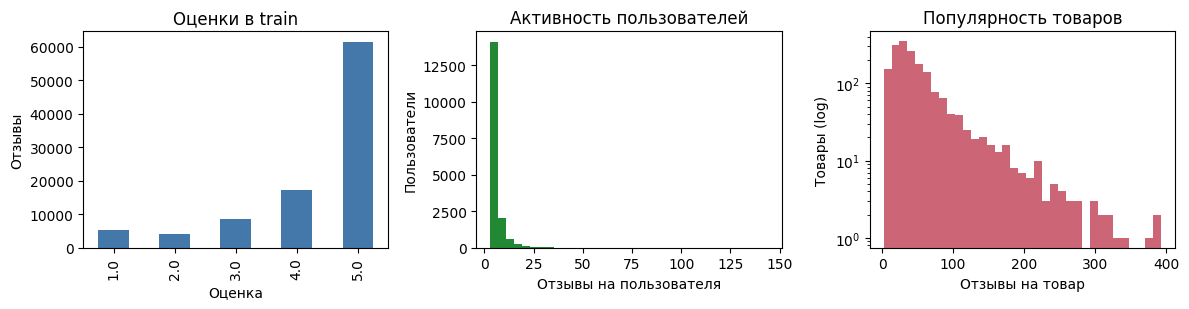

,Товары
Категория,
Games,891
Accessories,75
Consoles,63
Gaming Mice,51
Headsets,44
PC,34
Gamepads & Standard Controllers,30
Gaming Keyboards,29
Chargers,23


Разреженность train: 99.688%


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
train.rating.value_counts().sort_index().plot.bar(ax=axes[0], color="#4477aa")
axes[0].set(title="Оценки в train", xlabel="Оценка", ylabel="Отзывы")
user_activity = train.groupby("user_id").size()
axes[1].hist(user_activity, bins=35, color="#228833")
axes[1].set(title="Активность пользователей", xlabel="Отзывы на пользователя", ylabel="Пользователи")
item_activity = train.groupby("item_id").size()
axes[2].hist(item_activity, bins=35, log=True, color="#cc6677")
axes[2].set(title="Популярность товаров", xlabel="Отзывы на товар", ylabel="Товары (log)")
plt.tight_layout()
plt.show()

top_categories = metadata.category.value_counts().head(10)
display(top_categories.rename_axis("Категория").to_frame("Товары"))
print(f"Разреженность train: {1 - stats['Плотность train']:.3%}")


## Подготовка и оценка

Удаляю строки с пропусками в user/item/rating/time и оценки вне 1–5: без них нельзя задать корректное взаимодействие или порядок событий. Повторные пары user-item свожу к последнему отзыву, чтобы не учитывать пару несколько раз и сохранить актуальную оценку.

Фильтр 5-core итеративно оставляет пользователей и товары минимум с пятью отзывами; это уменьшает число редких объектов и даёт историю для временного разбиения. Для точной EASE беру 1 800 популярных товаров по первым 80% историй: плотная матрица Грама остаётся небольшой, отбор не использует validation/test. KNN и iALS работают с разреженными матрицами.

Если после фильтрации остаётся более 200 000 событий, выбираю целых пользователей с seed 42, чтобы ограничить расчёты, сохранив их истории и воспроизводимость. Здесь осталось 136 421 взаимодействие, поэтому дополнительная выборка пользователей не понадобилась.

Делю отзывы каждого пользователя по времени 80/10/10 на train/validation/test, чтобы не обучаться на будущих событиях. Кандидаты — товары из train; просмотренные товары исключаю. Релевантность — оценка не ниже 4. Считаю Recall@10 и NDCG@10; настройки выбираю по validation NDCG@10, test использую один раз после обучения на train и validation.

In [4]:
import numpy as np
import pandas as pd


class Popularity:
    """Простой baseline: ранжирование по числу позитивных train-оценок."""
    def fit(self, history, n_users, n_items):
        likes = history.loc[history.rating >= 4]
        self.scores = np.bincount(likes.item_id, minlength=n_items).astype(np.float32)
        self.n_items = n_items
        return self

    def score_users(self, user_ids):
        return np.broadcast_to(self.scores, (len(user_ids), self.n_items))


def evaluate(model, history, heldout, candidate_items, n_items, k=10, batch_size=128):
    """Macro Recall/NDCG/Precision; same warm catalog and seen-item rule for all."""
    candidates = np.asarray(candidate_items, dtype=np.int32)
    is_candidate = np.zeros(n_items, dtype=bool)
    is_candidate[candidates] = True
    positives = heldout.loc[heldout.rating >= 4, ["user_id", "item_id"]]
    positives = positives.loc[is_candidate[positives.item_id.to_numpy()]]
    truth_by_user = positives.groupby("user_id").item_id.apply(lambda x: set(map(int, x)))
    seen_by_user = {
        int(user): set(map(int, items))
        for user, items in history.groupby("user_id").item_id.agg(list).items()
    }
    users = np.asarray(sorted(map(int, truth_by_user.index)), dtype=np.int32)
    rows, recommended = [], set()
    discounts = 1 / np.log2(np.arange(2, k + 2))
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        score_block = model.score_users(batch)
        for row_idx, user in enumerate(batch):
            seen = seen_by_user.get(int(user), set())
            truth = truth_by_user.loc[int(user)] - seen
            if not truth:
                continue
            eligible = candidates[~np.isin(candidates, list(seen))]
            order = np.lexsort((eligible, -score_block[row_idx, eligible]))[:k]
            top = eligible[order]
            recommended.update(map(int, top))
            hits = np.array([int(item) in truth for item in top], dtype=np.float32)
            n_hits = float(hits.sum())
            ideal = discounts[:min(k, len(truth))].sum()
            rows.append({
                "user_id": int(user),
                "Recall@10": n_hits / len(truth),
                "NDCG@10": float(hits @ discounts[:len(hits)] / ideal),
                "Precision@10": n_hits / k,
            })
    detail = pd.DataFrame(rows)
    metrics = {name: float(detail[name].mean()) for name in ("Recall@10", "NDCG@10", "Precision@10")}
    metrics["Пользователи"] = len(detail)
    metrics["Позитивные события"] = int(len(positives))
    metrics["Покрытие каталога"] = len(recommended) / len(candidates)
    return metrics, detail


## Модели и короткие обоснования

1. ItemKNN. Косинусное сходство бинарных историй позитивных оценок уменьшаю множителем $\frac{n_{ij}}{n_{ij}+\gamma}$, где $\gamma$ — параметр сглаживания. Рекомендация складывает сходства товаров, понравившихся пользователю. Это простой способ учитывать совместные предпочтения.
2. iALS. Минимизирую $\sum_{u,i} c_{ui}(p_{ui}-\mathbf{x}_u^\top\mathbf{y}_i)^2+\lambda(\|\mathbf{X}\|_F^2+\|\mathbf{Y}\|_F^2)$, где $p_{ui}=\mathbf{1}[r_{ui}\ge4]$, а $c_{ui}=1+\alpha$ для наблюдаемого отзыва и $1$ для ненаблюдаемой пары. Модель использует неявные предпочтения.
3. EASE. Восстанавливаю бинарную матрицу позитивных оценок линейной моделью: $P=(X^\top X+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$, $B_{ii}=0$. Регуляризация нужна из-за корреляции товаров.
4. FM с метаданными. Оценка задаётся формулой $\hat y(\mathbf{x})=w_0+\sum_j w_jx_j+\sum_{j<l}\langle\mathbf{v}_j,\mathbf{v}_l\rangle x_jx_l$. Использую ID пользователя и товара, категорию, родительскую категорию и бренд, чтобы учесть признаки товара вместе с ID.
5. iALS с собственным сигналом. Меняю целевое предпочтение, сохраняя confidence базовой модели: $p_{ui}=\operatorname{clip}\!\left(\frac{r_{ui}-3}{2},0,1\right)\exp\!\left(-\frac{\ln 2\,a_{ui}}{h}\right)$, где $a_{ui}$ — возраст отзыва в днях, $h$ — период полураспада. Так более высокая и свежая оценка сильнее влияет на цель; сравниваю модель с базовым iALS по единому протоколу.

Все алгоритмы реализованы самостоятельно в models/ без готовых рекомендательных библиотек.

In [5]:
import time

import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from models.common import positive_matrix
from models.knn import ItemKNN
from models.ials import ImplicitALS
from models.custom_ials import CustomSignalALS
from models.ease import EASE
from models.fm import FactorizationMachine

def fit_knn(history, config):
    model = ItemKNN(**config)
    return model.fit(positive_matrix(history, n_users, n_items))

def fit_ials(history, config):
    model = ImplicitALS(n_factors=16, n_iters=config.get("n_iters", 12), reg=0.1, random_state=SEED, alpha=config["alpha"])
    return model.fit(history, n_users, n_items)

def fit_ease(history, config):
    model = EASE(**config)
    return model.fit(positive_matrix(history, n_users, n_items))

def fit_fm(history, config):
    model = FactorizationMachine(
        n_factors=config["n_factors"], epochs=12, batch_size=2048,
        use_metadata=config["use_metadata"], random_state=SEED,
    )
    return model.fit(history, n_users, n_items, metadata)

def fit_custom(history, config):
    model = CustomSignalALS(n_factors=16, n_iters=config.get("n_iters", 12), reg=0.1, alpha=20,
                            random_state=SEED, half_life_days=config["half_life_days"])
    return model.fit(history, n_users, n_items)

fitters = {
    "ItemKNN": fit_knn,
    "iALS": fit_ials,
    "EASE": fit_ease,
    "FM + метаданные": fit_fm,
    "iALS + свой сигнал": fit_custom,
}
search_space = {
    "ItemKNN": [{"n_neighbors": n, "shrinkage": 20.0} for n in (50, 100)],
    "iALS": [{"alpha": a, "n_iters": iters} for a in (10.0, 40.0) for iters in (8, 16)],
    "EASE": [{"reg": r} for r in (100.0, 500.0)],
    "FM + метаданные": [{"n_factors": f, "use_metadata": True} for f in (16, 32)],
    "iALS + свой сигнал": [{"half_life_days": d, "n_iters": iters} for d in (90.0, 365.0) for iters in (8, 16)],
}

search_rows, selected, validation_models = [], {}, {}
for name, configs in search_space.items():
    rows = []
    for config in configs:
        started = time.perf_counter()
        with threadpool_limits(limits=1):
            model = fitters[name](train, config)
        metrics, _ = evaluate(model, train, validation, candidate_items, n_items)
        row = {"Модель": name, "Параметры": str(config),
               "NDCG@10": metrics["NDCG@10"], "Recall@10": metrics["Recall@10"],
               "Время обучения, с": time.perf_counter() - started}
        search_rows.append(row)
        rows.append((metrics["NDCG@10"], config, model))
    _, selected[name], validation_models[name] = max(rows, key=lambda row: row[0])

validation_results = pd.DataFrame(search_rows).sort_values(["Модель", "NDCG@10"], ascending=[True, False])
display(validation_results.round(4))
print("Выбранные параметры:", selected)

fm_id_config = {"n_factors": selected["FM + метаданные"]["n_factors"], "use_metadata": False}
fm_id_validation_model = fit_fm(train, fm_id_config)
fm_id_valid, _ = evaluate(fm_id_validation_model, train, validation, candidate_items, n_items)
print(f"Validation FM без метаданных: NDCG@10={fm_id_valid['NDCG@10']:.4f}")

final_history = pd.concat([train, validation], ignore_index=True)
final_models = {"Popularity baseline": Popularity().fit(final_history, n_users, n_items)}
for name, config in selected.items():
    with threadpool_limits(limits=1):
        final_models[name] = fitters[name](final_history, config)
with threadpool_limits(limits=1):
    final_models["FM без метаданных"] = fit_fm(final_history, fm_id_config)

test_rows, test_details = [], {}
for name, model in final_models.items():
    metrics, details = evaluate(model, final_history, test, candidate_items, n_items)
    test_rows.append({"Модель": name, **metrics,
                      "Параметры": str(selected.get(name, fm_id_config if name == "FM без метаданных" else {}))})
    test_details[name] = details

test_results = pd.DataFrame(test_rows).set_index("Модель")
display(test_results[["Recall@10", "NDCG@10", "Precision@10", "Покрытие каталога", "Пользователи", "Параметры"]].round(4))

winner = test_results["NDCG@10"].idxmax()
metadata_delta = test_results.loc["FM + метаданные", "NDCG@10"] - test_results.loc["FM без метаданных", "NDCG@10"]
signal_delta = test_results.loc["iALS + свой сигнал", "NDCG@10"] - test_results.loc["iALS", "NDCG@10"]
print(f"Лучший NDCG@10: {winner} ({test_results.loc[winner, 'NDCG@10']:.4f}).")
print(f"FM с метаданными минус FM по ID: ΔNDCG@10={metadata_delta:+.4f}.")
print(f"Кастомный iALS минус базовый iALS: ΔNDCG@10={signal_delta:+.4f}.")


,Модель,Параметры,NDCG@10,Recall@10,"Время обучения, с"
6,EASE,{'reg': 100.0},0.0958,0.1678,3.6985
7,EASE,{'reg': 500.0},0.0916,0.1629,3.7379
8,FM + метаданные,"{'n_factors': 16, 'use_metadata': True}",0.0031,0.0060,10.5670
9,FM + метаданные,"{'n_factors': 32, 'use_metadata': True}",0.0018,0.0043,12.6882
1,ItemKNN,"{'n_neighbors': 100, 'shrinkage': 20.0}",0.0936,0.1645,1.8231
0,ItemKNN,"{'n_neighbors': 50, 'shrinkage': 20.0}",0.0932,0.1640,1.7088
2,iALS,"{'alpha': 10.0, 'n_iters': 8}",0.0678,0.1272,5.1594
3,iALS,"{'alpha': 10.0, 'n_iters': 16}",0.0671,0.1266,7.8810
5,iALS,"{'alpha': 40.0, 'n_iters': 16}",0.0658,0.1253,7.9885
4,iALS,"{'alpha': 40.0, 'n_iters': 8}",0.0637,0.1204,5.1554


Выбранные параметры: {'ItemKNN': {'n_neighbors': 100, 'shrinkage': 20.0}, 'iALS': {'alpha': 10.0, 'n_iters': 8}, 'EASE': {'reg': 100.0}, 'FM + метаданные': {'n_factors': 16, 'use_metadata': True}, 'iALS + свой сигнал': {'half_life_days': 365.0, 'n_iters': 16}}


Validation FM без метаданных: NDCG@10=0.0157


,Recall@10,NDCG@10,Precision@10,Покрытие каталога,Пользователи,Параметры
Модель,,,,,,
Popularity baseline,0.0241,0.0134,0.0030,0.0089,14248,{}
ItemKNN,0.1418,0.0828,0.0155,0.9120,14248,"{'n_neighbors': 100, 'shrinkage': 20.0}"
iALS,0.1057,0.0556,0.0117,0.2506,14248,"{'alpha': 10.0, 'n_iters': 8}"
EASE,0.1523,0.0866,0.0167,0.8892,14248,{'reg': 100.0}
FM + метаданные,0.0094,0.0043,0.0011,0.1442,14248,"{'n_factors': 16, 'use_metadata': True}"
iALS + свой сигнал,0.1117,0.0624,0.0128,0.2762,14248,"{'half_life_days': 365.0, 'n_iters': 16}"
FM без метаданных,0.0286,0.0151,0.0032,0.8820,14248,"{'n_factors': 16, 'use_metadata': False}"


Лучший NDCG@10: EASE (0.0866).
FM с метаданными минус FM по ID: ΔNDCG@10=-0.0108.
Кастомный iALS минус базовый iALS: ΔNDCG@10=+0.0068.


## Выводы

- Лучший результат дала EASE: NDCG@10 = 0,0866, Recall@10 = 0,1523. ItemKNN близка: NDCG@10 = 0,0828.
- FM с метаданными получила NDCG@10 = 0,0043 — ниже baseline (0,0134) и FM только с ID (0,0151). Дополнительные эпохи не устранили слабый результат; признаки товара могли оказаться недостаточно полезными для этих коротких историй.
- Кастомный iALS получил NDCG@10 = 0,0624 против 0,0556 у базового iALS; прирост составил 0,0068.

Оценка относится к известным пользователям и товарам из выбранного каталога.
